DNA SEQUENCE ANALYSIS
----------------------------------------
DNA Sequence: ATGAAACCCGGGTTTATGCCCTAA

1. BASIC SEQUENCE MANIPULATION
Sequence Length: 24
Complementary Sequence: TACTTTGGGCCCAAATACGGGATT
Reverse Sequence: AATCCCGTATTTGGGCCCAAAGTA
Reverse Complement: TTAGGGCATAAACCCGGGTTTCAT

2. NUCLEOTIDE COUNT
A: 7
T: 6
G: 5
C: 6

3. MOTIF ANALYSIS
Motif: ATG
Motif Count: 2
Motif Positions (1-based): [1, 16]

4. GC CONTENT
G Count: 5
C Count: 6
GC Content: 45.83 %

5. POTENTIAL CODING REGIONS

Region 1:
Start Position: 1
End Position: 24
Reading Frame (0-based): 0
Length: 24 nucleotides
Sequence: ATGAAACCCGGGTTTATGCCCTAA

Region 2:
Start Position: 16
End Position: 24
Reading Frame (0-based): 0
Length: 9 nucleotides
Sequence: ATGCCCTAA

6. NUCLEOTIDE COUNT GRAPH


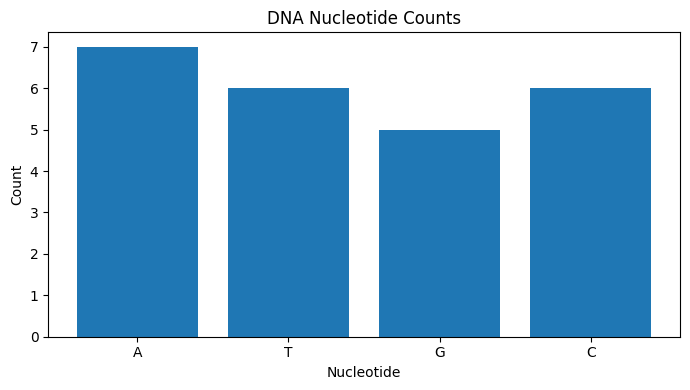

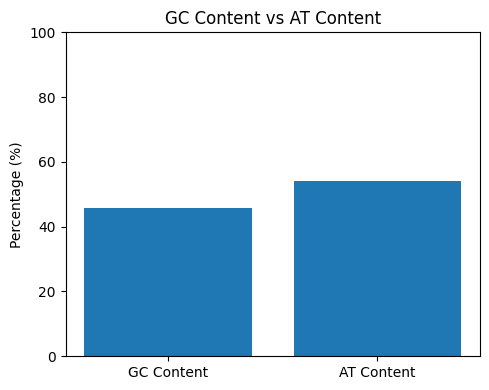


7. FINAL SUMMARY
Total Nucleotides: 24
Total Motif Occurrences: 2
GC Content: 45.83 %
Potential Coding Regions Found: 2


In [1]:
import matplotlib.pyplot as plt

dna = "ATGAAACCCGGGTTTATGCCCTAA"

dna = dna.upper()
valid_bases = set("ATGC")

if not dna or not set(dna).issubset(valid_bases):
    raise ValueError("Invalid DNA sequence! Use only A, T, G, C.")

print("DNA SEQUENCE ANALYSIS")
print("-" * 40)
print("DNA Sequence:", dna)

print("\n1. BASIC SEQUENCE MANIPULATION")
print("Sequence Length:", len(dna))

complement_table = str.maketrans("ATGC", "TACG")
complement = dna.translate(complement_table)

print("Complementary Sequence:", complement)
print("Reverse Sequence:", dna[::-1])
print("Reverse Complement:", complement[::-1])

print("\n2. NUCLEOTIDE COUNT")

bases = ["A", "T", "G", "C"]
base_counts = {base: dna.count(base) for base in bases}

for base, count in base_counts.items():
    print(f"{base}: {count}")

print("\n3. MOTIF ANALYSIS")

motif = "ATG"

positions = [
    i for i in range(len(dna) - len(motif) + 1)
    if dna[i:i + len(motif)] == motif
]

print("Motif:", motif)
print("Motif Count:", len(positions))
print("Motif Positions (1-based):", [p + 1 for p in positions])

print("\n4. GC CONTENT")

g_count = dna.count("G")
c_count = dna.count("C")

gc_content = (g_count + c_count) / len(dna) * 100

print("G Count:", g_count)
print("C Count:", c_count)
print("GC Content:", round(gc_content, 2), "%")

print("\n5. POTENTIAL CODING REGIONS")

start_codon = "ATG"
stop_codons = {"TAA", "TAG", "TGA"}

coding_regions = []

for frame in range(3):
    for start in range(frame, len(dna) - 2, 3):
        if dna[start:start + 3] == start_codon:
            # Find the first in-frame stop codon
            for end in range(start + 3, len(dna) - 2, 3):
                codon = dna[end:end + 3]

                if codon in stop_codons:
                    coding_regions.append({
                        "start": start + 1,
                        "end": end + 3,
                        "sequence": dna[start:end + 3],
                        "length": end + 3 - start,
                        "frame": frame
                    })
                    break

if coding_regions:
    for i, region in enumerate(coding_regions, start=1):
        print(f"\nRegion {i}:")
        print("Start Position:", region["start"])
        print("End Position:", region["end"])
        print("Reading Frame (0-based):", region["frame"])
        print("Length:", region["length"], "nucleotides")
        print("Sequence:", region["sequence"])
else:
    print("No complete start-to-stop ORF found in forward frames.")

print("\n6. NUCLEOTIDE COUNT GRAPH")

plt.figure(figsize=(7, 4))
plt.bar(base_counts.keys(), base_counts.values())
plt.title("DNA Nucleotide Counts")
plt.xlabel("Nucleotide")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
plt.bar(["GC Content", "AT Content"],
        [gc_content, 100 - gc_content])
plt.title("GC Content vs AT Content")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("\n7. FINAL SUMMARY")
print("Total Nucleotides:", len(dna))
print("Total Motif Occurrences:", len(positions))
print("GC Content:", round(gc_content, 2), "%")
print("Potential Coding Regions Found:", len(coding_regions))
